In [1]:
# Import required librabries...

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Load the Dataset...

In [4]:
df=pd.read_csv("/content/customer_churn_classification.csv")
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,monthly_charges.1,tech_support,customer_id,gender,monthly_charges.2,monthly_charges.3,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,86.76,No,C10119,Male,86.76,86.76,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,109.03,No,C10012,Male,109.03,109.03,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,67.40,No,NaN,Female,67.40,67.40,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,81.81,NaN,NaN,ale,81.81,81.81,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,61.18,o,C10236,Fmale,61.18,61.18,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,51.0,26.0,Two year,DS,1286.98,101.71,101.71,NaN,C10203,Mal,101.71,101.71,0.0,Credit card
258,77.0,66.0,NaN,SL,6985.19,55.06,55.06,Yes,C10087,MALE,55.06,55.06,1.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,97.23,N,C10072,NaN,97.23,97.23,0.0,Credit card
260,48.0,62.0,MONTH-TO-MONTH,o,NaN,NaN,NaN,No,C10235,Female,NaN,NaN,NaN,Bank transfer


In [5]:
print("Original shape:", df.shape)
display(df.head())
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Original shape: (262, 14)


,age,tenure_months,contract,internet_service,total_charges,monthly_charges,monthly_charges.1,tech_support,customer_id,gender,monthly_charges.2,monthly_charges.3,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,86.76,No,C10119,Male,86.76,86.76,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,109.03,No,C10012,Male,109.03,109.03,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,67.40,No,NaN,Female,67.40,67.40,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,81.81,NaN,NaN,ale,81.81,81.81,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,61.18,o,C10236,Fmale,61.18,61.18,1.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                233 non-null    float64
 1   tenure_months      241 non-null    float64
 2   contract           236 non-null    object 
 3   internet_service   240 non-null    object 
 4   total_charges      238 non-null    float64
 5   monthly_charges    233 non-null    float64
 6   monthly_charges.1  233 non-null    float64
 7   tech_support       238 non-null    object 
 8   customer_id        239 non-null    object 
 9   gender             242 non-null    object 
 10  monthly_charges.2  233 non-null    float64
 11  monthly_charges.3  233 non-null    float64
 12  churn              236 non-null    float64
 13  payment_method     245 non-null    object 
dtypes: float64(8), object(6)
memory usage: 28.8+ KB

Missing values:
 age                  29
tenure_months        21
contract

In [6]:
df = df.drop_duplicates().copy()
df = df.drop(columns=["monthly_charges.1", "monthly_charges.2",
                      "monthly_charges.3"], errors="ignore")
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,No,C10012,Male,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,No,NaN,Female,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,NaN,NaN,ale,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,o,C10236,Fmale,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,NaN,6249.12,23.93,NO,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DS,1286.98,101.71,NaN,C10203,Mal,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,N,C10072,NaN,0.0,Credit card
260,48.0,62.0,MONTH-TO-MONTH,o,NaN,NaN,No,C10235,Female,NaN,Bank transfer


In [7]:
# Remove unnecessary duplicate columns...

In [8]:
df = df.drop(columns=[
    'monthly_charges.1',
    'monthly_charges.2',
    'monthly_charges.3'
], errors='ignore')

df.head()

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,NaN,34.0,NaN,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,No,C10012,Male,1.0,ELECTRONIC CHECK
2,NaN,49.0,Two year,NaN,3434.07,67.40,No,NaN,Female,1.0,Electronic check
3,34.0,62.0,ONE YEAR,NaN,341.26,81.81,NaN,NaN,ale,1.0,Electroni check
4,52.0,24.0,NaN,NaN,3236.51,61.18,o,C10236,Fmale,1.0,NaN


In [9]:
# Handle inconsistent categorical values

In [10]:
df['gender'] = df['gender'].replace({
    'MALE': 'Male',
    'FEMALE': 'Female'
})

df['contract'] = df['contract'].replace({
    'MONTH-TO-MONTH': 'Month-to-month',
    'ONE YEAR': 'One year',
    'TWO YEAR': 'Two year'
})

df['internet_service'] = df['internet_service'].replace({
    'DSL': 'DSL',
    'Dsl': 'DSL',
    'NO': 'No',
    'FIBER OPTIC': 'Fiber optic'
})

df['tech_support'] = df['tech_support'].replace({
    'YES': 'Yes',
    'NO': 'No'
})

df['payment_method'] = df['payment_method'].replace({
    'BANK TRANSFER': 'Bank transfer',
    'CREDIT CARD': 'Credit card',
    'ELECTRONIC CHECK': 'Electronic check',
    'MAILED CHECK': 'Mailed check'
})

In [11]:
# Correct spelling inconsistencies

In [12]:
df['contract'] = df['contract'].replace({
    'To year': 'Two year',
    'Twoyear': 'Two year',
    'Two yer': 'Two year',
    'Two yea': 'Two year',
    'Month-t-month': 'Month-to-month',
    'Month-to-monh': 'Month-to-month',
    'Moth-to-month': 'Month-to-month',
    'onth-to-month': 'Month-to-month',
    'Monh-to-month': 'Month-to-month',
    'Monthto-month': 'Month-to-month',
    'One ear': 'One year',
    'ne year': 'One year',
    'wo year': 'Two year'
})

df['internet_service'] = df['internet_service'].replace({
    'o': 'No',
    'N': 'No',
    'SL': 'DSL',
    'DL': 'DSL',
    'DS': 'DSL',
    'Fiber opti': 'Fiber optic',
    'Fiber ptic': 'Fiber optic',
    'Fiber optc': 'Fiber optic',
    'iber optic': 'Fiber optic',
    'Fibe optic': 'Fiber optic',
    'Fiberoptic': 'Fiber optic'
})

df['tech_support'] = df['tech_support'].replace({
    'o': 'No',
    'N': 'No',
    'Ys': 'Yes',
    'Ye': 'Yes',
    'es': 'Yes'
})

df['gender'] = df['gender'].replace({
    'ale': 'Male',
    'Mae': 'Male',
    'Mle': 'Male',
    'Mal': 'Male',
    'Femae': 'Female',
    'Fmale': 'Female',
    'emale': 'Female',
    'Femle': 'Female',
    'Femal': 'Female',
    'Feale': 'Female'
})

df['payment_method'] = df['payment_method'].replace({
    'Credt card': 'Credit card',
    'Cedit card': 'Credit card',
    'Credit cad': 'Credit card',
    'Crdit card': 'Credit card',
    'Bank tranfer': 'Bank transfer',
    'Bak transfer': 'Bank transfer',
    'Mailed ceck': 'Mailed check',
    'Maled check': 'Mailed check',
    'Maild check': 'Mailed check',
    'Electroni check': 'Electronic check',
    'Eletronic check': 'Electronic check'
})

In [13]:
# Handle missing values

In [14]:
# Fill numerical missing values

In [15]:
df.isnull().sum()
num_cols = [
    'age',
    'tenure_months',
    'total_charges',
    'monthly_charges'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,NaN,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,NaN,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,NaN,3434.07,67.40,No,NaN,Female,1.0,Electronic check
3,34.0,62.0,One year,NaN,341.26,81.81,NaN,NaN,Male,1.0,Electronic check
4,52.0,24.0,NaN,NaN,3236.51,61.18,No,C10236,Female,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,NaN,6249.12,23.93,No,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DSL,1286.98,101.71,NaN,C10203,Male,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,No,C10072,NaN,0.0,Credit card
260,48.0,62.0,Month-to-month,No,4087.27,66.25,No,C10235,Female,NaN,Bank transfer


In [16]:
# fill categorical missing values...

In [17]:
cat_cols = [
    'contract',
    'internet_service',
    'tech_support',
    'gender',
    'payment_method'
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,Month-to-month,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,Fiber optic,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,Fiber optic,3434.07,67.40,No,NaN,Female,1.0,Electronic check
3,34.0,62.0,One year,Fiber optic,341.26,81.81,Yes,NaN,Male,1.0,Electronic check
4,52.0,24.0,Month-to-month,Fiber optic,3236.51,61.18,No,C10236,Female,1.0,Credit card
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,Fiber optic,6249.12,23.93,No,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DSL,1286.98,101.71,Yes,C10203,Male,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,No,C10072,Female,0.0,Credit card
260,48.0,62.0,Month-to-month,No,4087.27,66.25,No,C10235,Female,NaN,Bank transfer


In [18]:
#Handle missing churn and customer ID

In [19]:
df['churn'] = df['churn'].fillna(df['churn'].mode()[0])

df['customer_id'] = df['customer_id'].fillna('Unknown')

df

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,Month-to-month,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,Fiber optic,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,Fiber optic,3434.07,67.40,No,Unknown,Female,1.0,Electronic check
3,34.0,62.0,One year,Fiber optic,341.26,81.81,Yes,Unknown,Male,1.0,Electronic check
4,52.0,24.0,Month-to-month,Fiber optic,3236.51,61.18,No,C10236,Female,1.0,Credit card
...,...,...,...,...,...,...,...,...,...,...,...
256,72.0,12.0,Month-to-month,Fiber optic,6249.12,23.93,No,C10133,Male,1.0,Credit card
257,51.0,26.0,Two year,DSL,1286.98,101.71,Yes,C10203,Male,0.0,Credit card
259,51.0,22.0,Two year,Fiber optic,7395.50,97.23,No,C10072,Female,0.0,Credit card
260,48.0,62.0,Month-to-month,No,4087.27,66.25,No,C10235,Female,1.0,Bank transfer


In [20]:
# Handle outliers using IQR

In [21]:
num_cols = [
    'age',
    'tenure_months',
    'total_charges',
    'monthly_charges'
]

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

age Outliers: 0
tenure_months Outliers: 0
total_charges Outliers: 0
monthly_charges Outliers: 0


In [22]:
#Visualize outliers using box plots

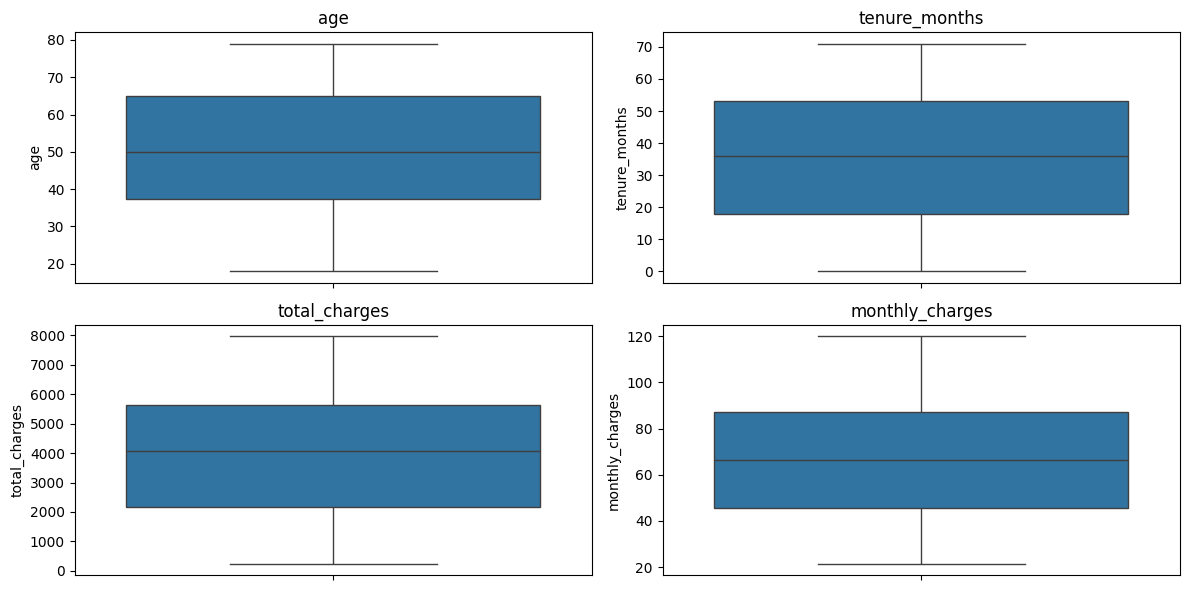

In [23]:
plt.figure(figsize=(12, 6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [24]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [25]:
#Final cleaned dataset...

In [26]:
df.isnull().sum()

,0
age,0
tenure_months,0
contract,0
internet_service,0
total_charges,0
monthly_charges,0
tech_support,0
customer_id,0
gender,0
churn,0


In [27]:
# now check duplicate records

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
# Displaying cleaned dataset

In [30]:
df.head()

,age,tenure_months,contract,internet_service,total_charges,monthly_charges,tech_support,customer_id,gender,churn,payment_method
0,50.0,34.0,Month-to-month,No,865.73,86.76,No,C10119,Male,1.0,Mailed check
1,54.0,32.0,Month-to-month,Fiber optic,3140.17,109.03,No,C10012,Male,1.0,Electronic check
2,50.0,49.0,Two year,Fiber optic,3434.07,67.40,No,Unknown,Female,1.0,Electronic check
3,34.0,62.0,One year,Fiber optic,341.26,81.81,Yes,Unknown,Male,1.0,Electronic check
4,52.0,24.0,Month-to-month,Fiber optic,3236.51,61.18,No,C10236,Female,1.0,Credit card


In [31]:
# save the cleaned dataset...

In [32]:
df.to_csv("cleaned_customer_churn.csv", index=False)

print("Dataset cleaned and saved successfully")

Dataset cleaned and saved successfully
